# 購買履歴から、これからの顧客価値を予測する

## 概要

『マーケティングサイエンスの理論と実践』第10章「優良顧客を見極める」を紹介する。過去の売上だけで顧客を評価する問題から始め、RFM、購買と離反の確率モデル、PythonによるLTV予測の順に説明する。LTVは、観測終了後に得られる期待粗利を現在価値に換算した合計である。

### 実行環境

Python 3.14.6、カーネル名は`wa-src(3.14.6)`である。必要なライブラリとバージョンは次のセルに表示する。上から順に実行でき、図は`10_nb_files`にSVG形式で保存する。外部データは不要である。

In [1]:
from importlib.metadata import version
from pathlib import Path
from pprint import pprint
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib_fontja  # 日本語フォントを設定する。
from matplotlib.ticker import FuncFormatter
from IPython.display import Latex, SVG, display
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import (
    summary_data_from_transaction_data,
    calibration_and_holdout_data,
)

print(f"Python {platform.python_version()} / wa-src(3.14.6)")
for package in ("numpy", "scipy", "pandas", "matplotlib", "matplotlib-fontja", "lifetimes"):
    print(f"{package}: {version(package)}")

# リポジトリのルート、またはノートブックのある場所から実行できる。
out_dir = Path("blog/10/10_nb_files") if Path("blog/10").is_dir() else Path("10_nb_files")
out_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
colors = ["#2563a6", "#d97935", "#358773"]


def sig3(value):
    """計算値を丸めず、表示だけを有効数字3桁にする。"""
    return "0" if value == 0 else f"{float(value):#.3g}".removesuffix(".")


def show_math(formula):
    r"""重要な式は \( ... \) で受け、LaTeXの出力欄へ表示する。"""
    formula = formula.strip()
    assert formula.startswith(r"\(") and formula.endswith(r"\)")
    display(Latex("$$\n" + formula[2:-2].strip() + "\n$$"))


def show_table(frame):
    print(frame.to_string(float_format=sig3))


def save_plot(fig, name):
    """軸の小数表記をそろえ、SVGを保存してノートブックにも埋め込む。"""
    formatter = FuncFormatter(lambda value, _: str(int(value)) if value == int(value) else sig3(value))
    for ax in fig.axes:
        if ax.xaxis.get_scale() == "linear":
            ax.xaxis.set_major_formatter(formatter)
        if ax.yaxis.get_scale() == "linear" and ax.get_ylabel() != "顧客ID":
            ax.yaxis.set_major_formatter(formatter)
    path = out_dir / f"{name}.svg"
    fig.savefig(path, format="svg", bbox_inches="tight")
    plt.close(fig)
    display(SVG(filename=str(path)))

Python 3.14.6 / wa-src(3.14.6)
numpy: 2.4.6
scipy: 1.18.1
pandas: 2.3.3
matplotlib: 3.11.2
matplotlib-fontja: 1.1.0
lifetimes: 0.11.3


## 1. 過去の優良顧客は、今後も購入するのか

本章の導入には、累計購買金額で選んだ上位会員に、長く購入していない顧客が含まれていた事例がある。一方、最近購入が増えた顧客は、累計額では上位に入らない。私は、会員ランクを見直す前に、この二つの顧客を確認することが必要だと考える。

顧客$i$の履歴を$H_i$、購買1回当たりの期待粗利を$\bar m_i$、将来の第$h$期の購買回数を$\Delta Y_{i,h}$、割引率を$d$とする。粗利と購買回数が独立なら、計画期間$K$のLTVは次式になる。

In [2]:
show_math(r"""\(
\begin{aligned}
E[\mathrm{LTV}_i^{(K)}\mid H_i]
&=\sum_{h=1}^{K}\frac{E[\bar m_i\Delta Y_{i,h}\mid H_i]}{(1+d)^h}\\
&=\sum_{h=1}^{K}\frac{\bar m_i E[\Delta Y_{i,h}\mid H_i]}{(1+d)^h}.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

購買回数の予測には、生存確率と購買率の両方が入る。生存とは「購買を継続し得る状態」を指す。解約手続きのないECでは離反を直接観測できないため、履歴から推定する。

新規獲得の採算では、獲得時点からのLTVと顧客獲得コストを同じ範囲で比較する。既存顧客の残存LTVを、過去の獲得費用と直接比較するわけではない。

## 2. RFMで履歴を整理する

通常のRFMは、最終購買からの経過期間、購買頻度、購買金額を使う。スコアで分類できるが、将来の購買回数を直接予測する仕組みではない。本章のモデルでは定義を次のように変える。

| 記号 | この実装での意味 |
|---|---|
| $x$ | 初回を除いた追加の購買日数 |
| $t_x$ | 初回から最終購買日までの経過週数 |
| $T$ | 初回から観測終了日までの経過週数 |
| $m$ | 初回購買日を除いた、購買日ごとの平均粗利 |

同じ日の取引は合計する。したがって、予測対象はレシートの枚数ではなく購買日数である。直近に買った顧客ほど$t_x$は$T$に近くなる。

## 3. 購買と離反を確率で表す

### Pareto/NBDからBG/NBDへ

Pareto/NBDは、生存中の購買をポアソン過程、離反までの期間を指数分布で表す。購買率と離反率の個人差には、それぞれガンマ分布を使う。

BG/NBDは購買の仕組みを引き継ぎ、離反を「追加購買の直後に一定確率で起きる」と置く。購買率$\lambda$と離反確率$\theta$は独立で、離反後は復帰しない。以下のガンマ分布の第2引数はレートである。

In [3]:
show_math(r"""\(
\lambda\sim\mathrm{Gamma}(r,\alpha),\qquad
\theta\sim\mathrm{Beta}(a,b),\qquad
E[\lambda]=\frac r\alpha,\quad E[\theta]=\frac a{a+b}.
\)""")

<IPython.core.display.Latex object>

### 生存と離反の尤度を足す

履歴が生じる可能性を、観測終了時に生存している場合$L_A$と、最終購買後に離反した場合$L_D$に分ける。購買時刻を含む履歴の尤度なので、回数だけのポアソン確率にある$x!$は現れない。

In [4]:
show_math(r"""\(
L_A=(1-\theta)^x\lambda^x e^{-\lambda T},\qquad
L_D=\theta(1-\theta)^{x-1}\lambda^x e^{-\lambda t_x}\quad(x>0).
\)""")

<IPython.core.display.Latex object>

個人差を平均する操作が周辺化である。$z$に$T$または$t_x$を入れ、$u=(\alpha+z)\lambda$と置換すると、購買率側の積分は次の順に整理できる。

In [5]:
show_math(r"""\(
\begin{aligned}
G(z)&=\int_0^\infty\lambda^x e^{-\lambda z}
\frac{\alpha^r\lambda^{r-1}e^{-\alpha\lambda}}{\Gamma(r)}\,d\lambda\\
&=\frac{\alpha^r}{\Gamma(r)}\int_0^\infty
\lambda^{r+x-1}e^{-(\alpha+z)\lambda}\,d\lambda\\
&=\frac{\alpha^r}{\Gamma(r)(\alpha+z)^{r+x}}
\int_0^\infty u^{r+x-1}e^{-u}\,du\\
&=\frac{\alpha^r\Gamma(r+x)}{\Gamma(r)(\alpha+z)^{r+x}}.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

離反側では、ベータ関数$B(a,b)=\int_0^1\theta^{a-1}(1-\theta)^{b-1}d\theta$を使う。指数を足し合わせ、ベータ関数の定義に戻す。

In [6]:
show_math(r"""\(
\begin{aligned}
A&=\frac1{B(a,b)}\int_0^1\theta^{a-1}(1-\theta)^{b+x-1}\,d\theta
=\frac{B(a,b+x)}{B(a,b)},\\
D&=\frac1{B(a,b)}\int_0^1\theta^a(1-\theta)^{b+x-2}\,d\theta
=\frac{B(a+1,b+x-1)}{B(a,b)},\\
\frac DA&=\frac{\Gamma(a+1)\Gamma(b+x-1)}{\Gamma(a)\Gamma(b+x)}
=\frac a{b+x-1},\\
P(\mathrm{alive}\mid x,t_x,T)
&=\frac{AG(T)}{AG(T)+DG(t_x)}\\
&=\left[1+\frac a{b+x-1}
\left(\frac{\alpha+T}{\alpha+t_x}\right)^{r+x}\right]^{-1}\quad(x>0).
\end{aligned}
\)""")

<IPython.core.display.Latex object>

最後の変形では$\Gamma(s+1)=s\Gamma(s)$と$G(z)$の比を使った。$x=0$では離反の項を含めず、生存確率は1になる。これはモデルの仮定であり、購入が1回だけの顧客が必ず戻るという意味ではない。

### 粗利はガンマ–ガンマモデルで予測する

購買日の粗利を$z_j$とし、$z_j\mid\nu\sim\mathrm{Gamma}(p,\nu)$、$\nu\sim\mathrm{Gamma}(q,v)$と置く。$x$日分の平均が$m$なら粗利合計は$xm$である。事後分布と期待粗利は次の形になる。

In [7]:
show_math(r"""\(
\begin{aligned}
\nu\mid x,m&\sim\mathrm{Gamma}(q+px,v+xm),\\
\bar m=E[p/\nu\mid x,m]
&=\frac{p(v+xm)}{px+q-1}\\
&=\frac{px}{px+q-1}m+
\frac{q-1}{px+q-1}\frac{pv}{q-1}\qquad(q>1).
\end{aligned}
\)""")

<IPython.core.display.Latex object>

ガンマ分布の逆数の平均は「レート÷（形状−1）」である。式を分けると、個人の実績と集団平均の加重平均になる。履歴が少ないほど集団平均に近づく。購買頻度と平均粗利の独立性も仮定する。

## 4. PythonでLTVを求める

### 4.1 取引を顧客別に集計する

本文と同じ乱数シードで3000人の模擬履歴を作る。全員が2022年1月1日に初回購入し、年末まで観測する設定である。売上から40%の粗利を計算する。実企業の実績ではなく、モデルの手順を確かめるためのデータである。

顧客数: 3000 / 取引件数: 26255
             frequency  recency    T  monetary_value
customer_id                                         
1                 22.0     50.9 52.0             673
2                 1.00     6.29 52.0             794
3                 1.00     46.9 52.0        2.89e+03
4                 6.00     7.57 52.0             453
5                 4.00     22.6 52.0        1.43e+03


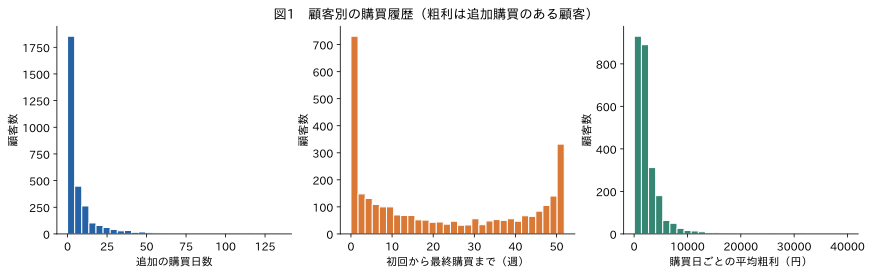

In [8]:
rng = np.random.default_rng(123)
n_customers = 3000
start, end = pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31")
observation_days = (end - start).days

# NumPyのガンマ分布には、レートの逆数であるscaleを渡す。
rates = rng.gamma(0.500, 1 / (1.25 * 7), n_customers)
dropout = rng.beta(0.500, 2.50, n_customers)
amount_rates = rng.gamma(3, 1 / 6000, n_customers)
rows = []

for customer, (rate, theta, nu) in enumerate(zip(rates, dropout, amount_rates), start=1):
    amount = max(1, int(rng.gamma(2, 1 / nu)))
    rows.append((customer, start, max(1, int(amount * 0.400))))
    if rate < 1.00e-8:
        continue
    elapsed = 0
    while True:
        elapsed += rng.exponential(1 / rate)
        if elapsed >= observation_days:
            break
        amount = max(1, int(rng.gamma(2, 1 / nu)))
        date = start + pd.Timedelta(days=int(elapsed))
        rows.append((customer, date, max(1, int(amount * 0.400))))
        if rng.random() < theta:
            break

transactions = pd.DataFrame(rows, columns=["customer_id", "date", "gross_profit"])
rfm = summary_data_from_transaction_data(
    transactions, "customer_id", "date", monetary_value_col="gross_profit",
    observation_period_end=end, freq="D", freq_multiplier=7,
)
print(f"顧客数: {len(rfm)} / 取引件数: {len(transactions)}")
show_table(rfm.head())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.70), layout="constrained")
for ax, column, label, color in zip(
    axes, ("frequency", "recency", "monetary_value"),
    ("追加の購買日数", "初回から最終購買まで（週）", "購買日ごとの平均粗利（円）"), colors,
):
    values = rfm.loc[rfm.frequency > 0, column] if column == "monetary_value" else rfm[column]
    ax.hist(values, bins=30, color=color, edgecolor="white")
    ax.set(xlabel=label, ylabel="顧客数")
fig.suptitle("図1　顧客別の購買履歴（粗利は追加購買のある顧客）")
save_plot(fig, "01_rfm")

### 4.2 BG/NBDを学習し、予測を確認する

図1では購買日数の少ない顧客が多い。モデルを当てはめ、同じ観測期間で再生成した購買日数と比較する。正則化は、推定値が極端になるのを抑える設定である。

{'a': '0.477', 'alpha': '1.51', 'b': '2.15', 'r': '0.526'}


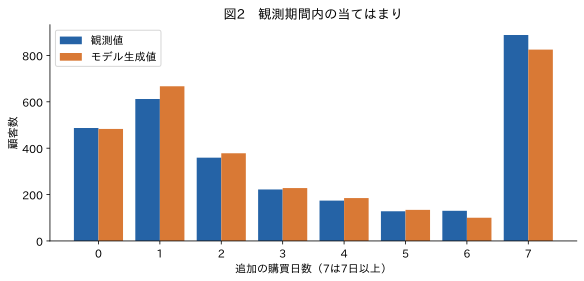

In [9]:
x, tx, age = rfm.frequency, rfm.recency, rfm["T"]
bg = BetaGeoFitter(penalizer_coef=0.00100).fit(x, tx, age)
pprint({name: sig3(value) for name, value in bg.params_.items()})

# 推定した分布から購買時刻を作り、元データと同様に購買日を数える。
check_rng = np.random.default_rng(456)
r, alpha, a, b = (bg.params_[name] for name in ("r", "alpha", "a", "b"))
check_rates = check_rng.gamma(r, 1 / (alpha * 7), len(rfm))
check_dropout = check_rng.beta(a, b, len(rfm))
generated = np.zeros(len(rfm), dtype=int)
for i, (rate, theta, weeks) in enumerate(zip(check_rates, check_dropout, age)):
    elapsed, days = 0, set()
    while rate > 1.00e-8:
        elapsed += check_rng.exponential(1 / rate)
        if elapsed >= weeks * 7:
            break
        if int(elapsed) > 0:
            days.add(int(elapsed))
        if check_rng.random() < theta:
            break
    generated[i] = len(days)

fig, ax = plt.subplots(figsize=(8, 3.80), layout="constrained")
positions = np.arange(8)
for shift, values, label, color in (
    (-0.200, x.to_numpy(dtype=int), "観測値", colors[0]),
    (0.200, generated, "モデル生成値", colors[1]),
):
    counts = np.bincount(np.minimum(values, 7), minlength=8)
    ax.bar(positions + shift, counts, width=0.400, color=color, label=label)
ax.set(xlabel="追加の購買日数（7は7日以上）", ylabel="顧客数", title="図2　観測期間内の当てはまり")
ax.set_xticks(positions)
ax.legend()
save_plot(fig, "02_fit")

図2は学習期間内の確認である。次は9月末までで別のモデルを学習し、10〜12月の実績と比較する。図3は学習期間の購買日数ごとの平均であり、個人ごとの誤差はMAEでも確認する。

検証期間のMAE: 0.761 日


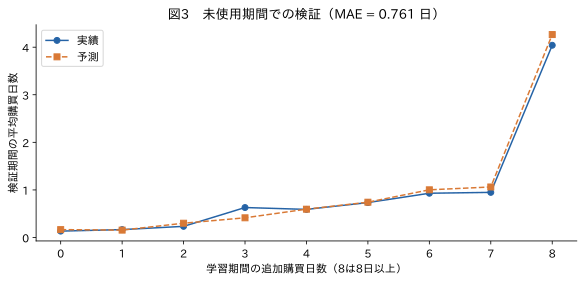

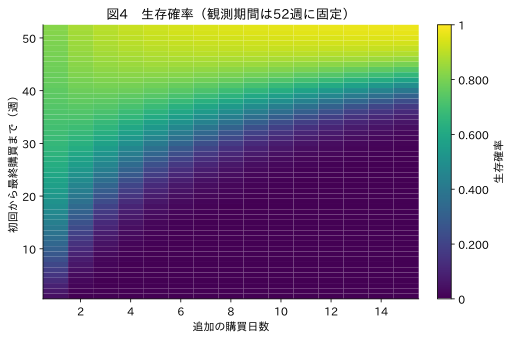

In [10]:
holdout = calibration_and_holdout_data(
    transactions, "customer_id", "date", calibration_period_end="2022-09-30",
    observation_period_end=end, freq="D", freq_multiplier=7,
)
bg_cal = BetaGeoFitter(penalizer_coef=0.00100).fit(
    holdout.frequency_cal, holdout.recency_cal, holdout.T_cal,
)
holdout["prediction"] = bg_cal.predict(
    holdout.duration_holdout.iloc[0],
    holdout.frequency_cal, holdout.recency_cal, holdout.T_cal,
)
mae = float(np.mean(np.abs(holdout.prediction - holdout.frequency_holdout)))
print(f"検証期間のMAE: {sig3(mae)} 日")
grouped = holdout.groupby(holdout.frequency_cal.clip(upper=8)).agg(
    actual=("frequency_holdout", "mean"), predicted=("prediction", "mean"),
    customers=("prediction", "size"),
)
fig, ax = plt.subplots(figsize=(8, 3.80), layout="constrained")
ax.plot(grouped.index, grouped.actual, "o-", color=colors[0], label="実績")
ax.plot(grouped.index, grouped.predicted, "s--", color=colors[1], label="予測")
ax.set(xlabel="学習期間の追加購買日数（8は8日以上）", ylabel="検証期間の平均購買日数",
       title=f"図3　未使用期間での検証（MAE = {sig3(mae)} 日）")
ax.legend()
save_plot(fig, "03_holdout")

# 生存確率は全観測期間で学習したbgを使う。
rfm["alive"] = bg.conditional_probability_alive(x, tx, age)
frequency_grid, recency_grid = np.meshgrid(np.arange(1, 16), np.arange(1, 53))
alive_grid = bg.conditional_probability_alive(frequency_grid, recency_grid, 52)
fig, ax = plt.subplots(figsize=(7, 4.60), layout="constrained")
mesh = ax.pcolormesh(frequency_grid, recency_grid, alive_grid, shading="nearest", cmap="viridis", vmin=0, vmax=1)
fig.colorbar(mesh, ax=ax, label="生存確率")
ax.set(xlabel="追加の購買日数", ylabel="初回から最終購買まで（週）",
       title="図4　生存確率（観測期間は52週に固定）")
save_plot(fig, "04_alive")

図4では、同じ頻度なら最終購買が最近の顧客ほど生存確率が高い。一方、高頻度だった顧客が長く買わない場合は、離反の可能性を高く評価する。

### 4.3 購買日数と粗利を予測する

将来$t$週の累積購買日数を$Y(t)$とする。生存している間の購買率を積分した期待値$C(t)$をライブラリで計算する。$I_s$は将来時点$T+s$で生存していれば1、離反済みなら0である。

<IPython.core.display.Latex object>

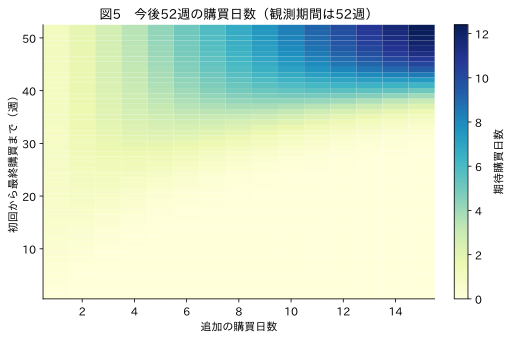

{'p': '1.94', 'q': '2.92', 'v': '2.47e+03'}
追加購買日数と平均粗利の相関: 0.0179


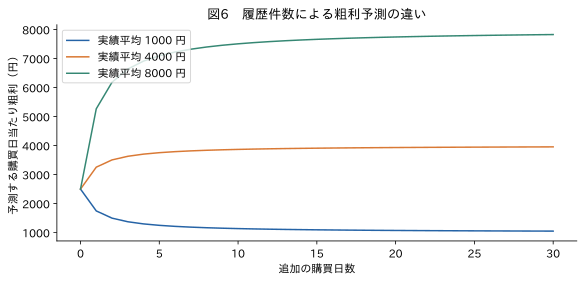

In [11]:
show_math(r"""\(
C(t)=E[Y(t)\mid H]=\int_0^t E[\lambda I_s\mid H]\,ds.
\)""")
rfm["purchases_52w"] = bg.predict(52, x, tx, age)
future_grid = bg.predict(52, frequency_grid, recency_grid, 52)
fig, ax = plt.subplots(figsize=(7, 4.60), layout="constrained")
mesh = ax.pcolormesh(frequency_grid, recency_grid, future_grid, shading="nearest", cmap="YlGnBu")
fig.colorbar(mesh, ax=ax, label="期待購買日数")
ax.set(xlabel="追加の購買日数", ylabel="初回から最終購買まで（週）",
       title="図5　今後52週の購買日数（観測期間は52週）")
save_plot(fig, "05_purchases")

# ガンマ–ガンマの学習には追加購買があり、平均粗利が正の顧客を使う。
repeat = rfm.loc[(x > 0) & (rfm.monetary_value > 0)]
gg = GammaGammaFitter(penalizer_coef=0).fit(repeat.frequency, repeat.monetary_value)
assert gg.params_["q"] > 1, "集団の期待粗利を有限にするためq > 1が必要である。"
pprint({name: sig3(value) for name, value in gg.params_.items()})
correlation = float(repeat.frequency.corr(repeat.monetary_value))
print(f"追加購買日数と平均粗利の相関: {sig3(correlation)}")
rfm["expected_profit"] = gg.conditional_expected_average_profit(x, rfm.monetary_value)

fig, ax = plt.subplots(figsize=(8, 3.80), layout="constrained")
counts = np.arange(31)
for observed, color in zip((1000, 4000, 8000), colors):
    estimate = gg.conditional_expected_average_profit(counts, observed)
    ax.plot(counts, estimate, color=color, label=f"実績平均 {observed} 円")
ax.set(xlabel="追加の購買日数", ylabel="予測する購買日当たり粗利（円）",
       title="図6　履歴件数による粗利予測の違い")
ax.legend()
save_plot(fig, "06_profit")

図5は生存確率だけでなく購買率も反映する。図6では、件数が少ない顧客の粗利予測が集団平均に近づく。相関が小さくても独立性が保証されるわけではない。

次に12か月分のLTVを求める。計算を追いやすくするため、ここでは1か月を30日とする。累積予測の差を取って月別の購買日数に直し、期待粗利を掛け、月次1%で割り引く。生存確率を再び掛ける必要はない。

<IPython.core.display.Latex object>

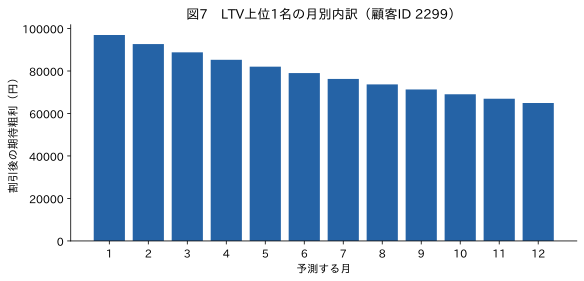

In [12]:
show_math(r"""\(
\begin{aligned}
t_h&=30h/7,\qquad E[\Delta Y_h\mid H]=C(t_h)-C(t_{h-1}),\\
\mathrm{LTV}^{(12)}&=\sum_{h=1}^{12}
\frac{\bar m\{C(t_h)-C(t_{h-1})\}}{(1+0.0100)^h}.
\end{aligned}
\)""")
months = np.arange(1, 13)
# 第0月を含む累積予測を作り、隣り合う月の差を取る。
cumulative = np.vstack([bg.predict(30 * month / 7, x, tx, age) for month in range(13)])
monthly_days = np.diff(cumulative, axis=0)
monthly_value = monthly_days * rfm.expected_profit.to_numpy() / (1 + 0.0100) ** months[:, None]
rfm["LTV"] = monthly_value.sum(axis=0)

top_customer = rfm.LTV.idxmax()
column = rfm.index.get_loc(top_customer)
fig, ax = plt.subplots(figsize=(8, 3.80), layout="constrained")
ax.bar(months, monthly_value[:, column], color=colors[0])
ax.set(xlabel="予測する月", ylabel="割引後の期待粗利（円）",
       title=f"図7　LTV上位1名の月別内訳（顧客ID {top_customer}）")
ax.set_xticks(months)
save_plot(fig, "07_monthly_ltv")

### 4.4 LTV順に並べて施策を考える

図7の12本の棒を足した値が、その顧客のLTVである。全顧客をLTV順に並べ、累積LTVの30%、60%、85%を境界に分類する。これは人数の割合ではない。

             frequency  alive  expected_profit      LTV   segment
customer_id                                                      
2299               114  0.937         1.16e+04 9.47e+05  Platinum
50                62.0  0.985         1.34e+04 6.27e+05  Platinum
2422              83.0  0.993         7.71e+03 4.87e+05  Platinum
1799              96.0  0.986         5.22e+03 3.78e+05  Platinum
1170               129  0.993         3.86e+03 3.78e+05  Platinum
          customers  mean_ltv  ltv_pct
segment                               
Platinum         31  2.72e+05     29.8
Gold            117  7.32e+04     30.2
Silver          329  2.16e+04     25.0
General        2523  1.69e+03     15.0


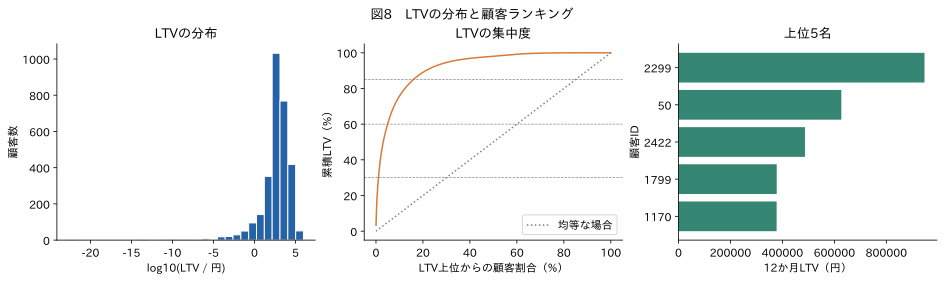

In [13]:
ranked = rfm.sort_values("LTV", ascending=False).copy()
ranked["cumulative_pct"] = ranked.LTV.cumsum() / ranked.LTV.sum() * 100
ranked["segment"] = pd.cut(
    ranked.cumulative_pct.clip(upper=100), bins=[0, 30, 60, 85, 100],
    labels=["Platinum", "Gold", "Silver", "General"], include_lowest=True,
)
show_table(ranked[["frequency", "alive", "expected_profit", "LTV", "segment"]].head())
summary = ranked.groupby("segment", observed=True).agg(
    customers=("LTV", "size"), mean_ltv=("LTV", "mean"), total_ltv=("LTV", "sum"),
)
summary["ltv_pct"] = summary.total_ltv / ranked.LTV.sum() * 100
show_table(summary.drop(columns="total_ltv"))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.80), layout="constrained")
positive = ranked.loc[ranked.LTV > 0, "LTV"]
axes[0].hist(np.log10(positive), bins=30, color=colors[0], edgecolor="white")
axes[0].set(xlabel="log10(LTV / 円)", ylabel="顧客数", title="LTVの分布")
customer_pct = np.arange(1, len(ranked) + 1) / len(ranked) * 100
axes[1].plot(customer_pct, ranked.cumulative_pct, color=colors[1])
axes[1].plot([0, 100], [0, 100], ":", color="gray", label="均等な場合")
for threshold in (30, 60, 85):
    axes[1].axhline(threshold, color="gray", linestyle="--", linewidth=0.700)
axes[1].set(xlabel="LTV上位からの顧客割合（%）", ylabel="累積LTV（%）", title="LTVの集中度")
axes[1].legend()
top = ranked.head(5).sort_values("LTV")
axes[2].barh(np.arange(5), top.LTV, color=colors[2])
axes[2].set_yticks(np.arange(5), [str(i) for i in top.index])
axes[2].set(xlabel="12か月LTV（円）", ylabel="顧客ID", title="上位5名")
fig.suptitle("図8　LTVの分布と顧客ランキング")
save_plot(fig, "08_ranking")

# 出力前に、予測の範囲とLTVの集計を確認する。
assert np.isfinite(rfm.select_dtypes(include="number")).all().all()
assert rfm.alive.between(0, 1).all()
assert np.allclose(rfm.loc[x == 0, "alive"], 1)
assert monthly_days.min() >= -1.00e-8 and (rfm.LTV >= 0).all()
assert np.allclose(monthly_days.sum(axis=0), bg.predict(360 / 7, x, tx, age))
assert ranked.segment.notna().all()

### 4.5 推定の幅も確認する

本文は最後にPyMC-Marketingでも推定し、MCMCの診断と期待LTVの94%信用区間を確認する。この区間は期待粗利を固定した条件でのBG/NBDパラメータの不確実性を表し、実現する利益の予測区間とは異なる。詳細なコードは[本書のサポートページ](https://github.com/gihyo-book/marketing_science_book)に収録されている。

## 結論

この記事では、購買履歴から生存確率、将来の購買日数、期待粗利を推定し、LTVで顧客を順位付けする流れを紹介した。

LTVは施策の対象を考える材料であり、クーポンで増える利益を直接示さない。私は、順位だけで配布先を決めず、対象を分けた比較で追加利益と費用を確かめる必要があると考える。

[『マーケティングサイエンスの理論と実践』](https://gihyo.jp/book/2026/978-4-297-16025-8)では、これらの仮定や導出、実装と結果の解釈を順に説明している。自社の購買履歴で何を予測できるかを整理する際に参照できる。

参考文献：Fader, Hardie, Lee（2005）[“Counting Your Customers” the Easy Way](https://www.brucehardie.com/papers/018/fader_et_al_mksc_05.pdf), Marketing Science, 24(2), 275–284。